# 02 · RP-PCA — risk-premium PCA (Lettau & Pelger, 2020)

**Purpose.** Estimate factors that explain both the **time series** and the
**cross-section of expected returns**. RP-PCA adds a penalty on pricing errors
to PCA and thereby detects weak factors with high Sharpe ratios.

**Specification.** Factor weights are the top-$K$ eigenvectors of

$$\hat\Sigma_{RP}=\tfrac1T R'R+\gamma\,\bar R\bar R'=\hat\Sigma_R+(1+\gamma)\bar R\bar R'.$$

$\gamma=-1$ is covariance PCA, $\gamma=0$ second-moment PCA; Lettau-Pelger use
$\gamma=10$. RP-PCA equals TS-target PCA with the mean target $G=1_T$.

| Parameter | Default | Options |
|---|---|---|
| `n_factors` | 1 | number of factors |
| `gamma` | 10.0 | risk-premium weight, $\ge -1$ |
| `standardize` | `False` | Lettau-Pelger's weighting $Q=\mathrm{diag}(1/\sigma_i)$ |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
R = sim.returns

## 1. The effect of γ when all factors are strong

In the default simulation all three factors are *strong* (they lie above the
noise level, see section 2), so PCA already finds them. As γ grows the
estimator rotates within the factor space towards average returns: the
in-sample Sharpe ratio rises and pricing errors fall, while the explained
time-series variation is unchanged. Recovery of the factor space does **not**
improve here — there is nothing left to find.

In [3]:
from latent_factor_models.evaluation import generalized_correlation

gammas = [-1, 0, 2, 5, 10, 20, 50, 100]
rows = []
for g in gammas:
    m = lfm.RPPCA(3, gamma=g).fit(R)
    ev = m.evaluate()
    ev["factor-space recovery"] = generalized_correlation(m.factors_, sim.factors)[-1]
    rows.append(ev)
table = pd.DataFrame(rows, index=pd.Index(gammas, name="gamma"))
table

,sharpe_ratio,rms_alpha,unexplained_variation,total_r2,factor-space recovery
gamma,,,,,
-1,0.3210,0.1311,0.3371,0.7060,0.9085
0,0.3311,0.1288,0.3371,0.7060,0.9086
2,0.3463,0.1260,0.3371,0.7060,0.9075
5,0.3609,0.1237,0.3372,0.7059,0.9051
10,0.3742,0.1221,0.3373,0.7058,0.9017
20,0.3858,0.1210,0.3375,0.7056,0.8977
50,0.3959,0.1202,0.3376,0.7055,0.8934
100,0.4000,0.1198,0.3377,0.7054,0.8914


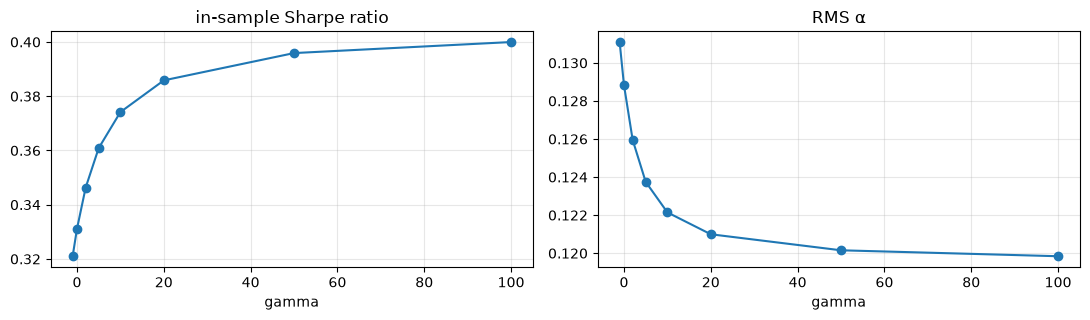

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
table["sharpe_ratio"].plot(ax=ax[0], marker="o", title="in-sample Sharpe ratio")
table["rms_alpha"].plot(ax=ax[1], marker="o", title="RMS α")
plt.tight_layout();

## 2. Where RP-PCA matters: a genuinely weak factor

A factor is invisible to PCA when its signal eigenvalue is below the edge of the
noise spectrum. With unit-variance loadings, factor volatility $\sigma_f$ and
idiosyncratic volatility $\sigma_e$, the signal is about $N\sigma_f^2$ and the
noise edge $\sigma_e^2(1+\sqrt{N/T})^2$ (Marchenko-Pastur). RP-PCA adds the
mean term $(1+\gamma)N\mu_f^2$, which lifts a weak but **highly priced**
factor above the edge (Lettau-Pelger, Theorem 2).

Below: a third factor with volatility 0.2 and Sharpe ratio 0.6, averaged over
20 simulated samples; models are estimated on 400 months and evaluated out of
sample on the remaining 200.

In [5]:
N, T, sigma_e, vol3, sr3 = 100, 600, 3.0, 0.2, 0.6
print(
    f"signal N·σ² = {N * vol3**2:.1f}  <  noise edge = {sigma_e**2 * (1 + np.sqrt(N / T)) ** 2:.1f}"
    f"  ->  PCA cannot detect factor 3"
)

grid = [-1, 0, 2, 5, 10, 20, 50]
recovery = {g: [] for g in grid}
oos_sr = {g: [] for g in grid}
for s in range(20):
    sim_w = lfm.simulate_factor_returns(
        T=T, N=N, factor_vol=(4, 2, vol3), sharpe=(0.12, 0.05, sr3), idio_vol=sigma_e, seed=s
    )
    for g in grid:
        m = lfm.RPPCA(3, gamma=g).fit(sim_w.returns[:400])
        recovery[g].append(generalized_correlation(m.factors_, sim_w.factors[:400])[-1])
        oos_sr[g].append(m.evaluate(sim_w.returns[400:])["sharpe_ratio"])
weak = pd.DataFrame(
    {
        "recovery of weak factor": pd.Series(recovery).map(np.mean),
        "out-of-sample Sharpe": pd.Series(oos_sr).map(np.mean),
    }
)
weak.index.name = "gamma"
weak

signal N·σ² = 4.0  <  noise edge = 17.8  ->  PCA cannot detect factor 3


,recovery of weak factor,out-of-sample Sharpe
gamma,,
-1,0.2220,0.1785
0,0.2889,0.2218
2,0.4107,0.2917
5,0.4039,0.2884
10,0.3914,0.2819
20,0.3826,0.2772
50,0.3764,0.2738


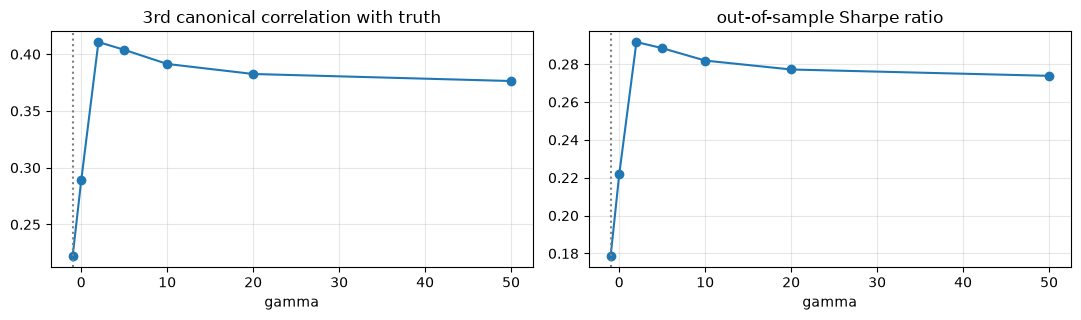

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
weak["recovery of weak factor"].plot(
    ax=ax[0], marker="o", title="3rd canonical correlation with truth"
)
weak["out-of-sample Sharpe"].plot(ax=ax[1], marker="o", title="out-of-sample Sharpe ratio")
for a in ax:
    a.axvline(-1, color="grey", ls=":")  # PCA
plt.tight_layout();

RP-PCA roughly doubles the recovery of the weak factor and raises the
out-of-sample Sharpe ratio by about 60 % relative to PCA (γ = −1). The optimum
is interior: very large γ over-weights noisy sample means. This is why γ is
chosen by cross-validation (next section) rather than set as large as possible.

## 3. Choosing γ by cross-validation

Contiguous 5-fold cross-validation of the out-of-fold Sharpe ratio (each fold
fitted on the remaining periods). Any scorer can be used:
`"sharpe"`, `"neg_rms_alpha"`, `"neg_unexplained_variation"`, `"total_r2"`, or a
callable `score(fitted_model, test_data)`.

In [7]:
gs = lfm.GridSearchCV(
    lfm.RPPCA(3), {"gamma": gammas, "n_factors": [3, 4]}, cv=lfm.KFold(5), scoring="sharpe"
).fit(R)
print("best:", gs.best_params_, "CV Sharpe:", round(gs.best_score_, 4))
pd.DataFrame(gs.result_.to_records()).pivot(index="gamma", columns="n_factors", values="mean_score")

best: {'gamma': 5, 'n_factors': 3} CV Sharpe: 0.2894


n_factors,3,4
gamma,,
-1,0.2862,0.2797
0,0.2876,0.2770
2,0.2889,0.2672
5,0.2894,0.2392
10,0.2891,0.2219
20,0.2882,0.2105
50,0.2869,0.2029
100,0.2863,0.2002


## 4. Rolling out-of-sample comparison (Lettau-Pelger protocol)

240-month rolling window, re-estimated every month; returns of month $t+1$ are
priced with weights, loadings and tangency weights estimated through $t$.
`oos_loadings="projection"` reproduces Lettau-Pelger's pricing with the
eigenvector loadings; `"ols"` (default) uses the window's time-series betas.

In [8]:
engine = lfm.Engine(
    [lfm.PCA(3), lfm.RPPCA(3, gamma=10), lfm.RPPCA(3, gamma=gs.best_params_["gamma"])]
)
res = engine.out_of_sample(R, window=240, refit_every=1, oos_loadings="projection")
res.to_frame().set_index("model")

,sample,sharpe_ratio,rms_alpha,unexplained_variation,total_r2,n_windows
model,,,,,,
PCA(n_factors=3),out-of-sample,0.2763,0.1742,0.3505,0.6936,360
RPPCA(n_factors=3),out-of-sample,0.2908,0.1457,0.3533,0.6911,360
"RPPCA(n_factors=3,gamma=5)",out-of-sample,0.2901,0.1448,0.3520,0.6923,360


## 5. Diagnostics and variants

In [9]:
rp = lfm.RPPCA(3, gamma=10).fit(R)
pc = lfm.PCA(3).fit(R)
pd.DataFrame(
    {"RP-PCA signal": rp.variance_signal(), "PCA signal": pc.variance_signal()},
    index=["F1", "F2", "F3"],
)

,RP-PCA signal,PCA signal
F1,204.4706,204.2220
F2,51.5193,43.2746
F3,12.8293,6.5528


In [10]:
# Lettau-Pelger's empirical version: volatility-weighted RP-PCA
pd.Series(lfm.RPPCA(3, gamma=10, standardize=True).fit(R).evaluate(), name="standardised RP-PCA")

sharpe_ratio             0.3767
rms_alpha                0.1206
unexplained_variation    0.3361
total_r2                 0.7044
Name: standardised RP-PCA, dtype: float64

**Validation.** Identical to the authors' `rpPCA_cv.m` (Giglio-Xiu-Zhang code)
and to the independent `rppca` package (see `docs/validation.md`).
**References.** Lettau & Pelger (2020, *JEcon*; *RFS*).